# 01 · Exploratory Data Analysis: UCI Heart Disease (Cleveland)

**Goal:** understand the data well enough to make the preprocessing and modelling decisions in Phase 2.

The data comes from `make data`, which downloads the raw UCI file, verifies its SHA-256 checksum and writes `data/processed/heart.csv`. The figures are generated by `heart.eda`, the same code `make eda` runs, so the notebook and the report never drift apart.

In [1]:
import pandas as pd
from IPython.display import Image, display

from heart.config import BINARY_FEATURES, CATEGORICAL_FEATURES, NUMERIC_FEATURES, TARGET
from heart.data import invalid_rows, load_processed, load_raw
from heart.eda import make_all_figures

pd.set_option("display.precision", 2)
raw = load_raw()
df = load_processed()
print(f"raw: {raw.shape}, processed: {df.shape}")
df.head()

raw: (303, 14), processed: (303, 14)


,age,trestbps,chol,thalach,oldpeak,cp,restecg,slope,ca,thal,sex,fbs,exang,target
0,63.0,145.0,233.0,150.0,2.3,1,2,3,0,6,1,1,0,0
1,67.0,160.0,286.0,108.0,1.5,4,2,2,3,3,1,0,1,1
2,67.0,120.0,229.0,129.0,2.6,4,2,2,2,7,1,0,1,1
3,37.0,130.0,250.0,187.0,3.5,3,0,3,0,3,1,0,0,0
4,41.0,130.0,204.0,172.0,1.4,2,2,1,0,3,0,0,0,0


## 1. Data quality
- The raw file has no header and uses `?` for missing values. `load_raw` maps `?` → NaN.
- We check for duplicates and for values outside clinically plausible ranges or the documented UCI codes.

In [2]:
print("duplicate rows:", raw.duplicated().sum())
print("invalid rows:  ", invalid_rows(raw).sum())
missing = df.isna().sum()
missing[missing > 0].to_frame("missing").assign(pct=lambda m: m["missing"] / len(df) * 100)

duplicate rows: 0
invalid rows:   0


,missing,pct
ca,4,1.32
thal,2,0.66


In [3]:
df[NUMERIC_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


**Findings**
- No duplicates and no out-of-range values, so all 303 rows are kept.
- Only 6 missing values (`ca`: 4, `thal`: 2, under 2% of rows). We **don't drop or fill them here**. Imputation goes inside the model pipeline (Phase 2), so it learns its statistics from training folds only and runs identically at prediction time.
- The numeric features sit on very different scales (cholesterol around 250, ST depression around 1), so linear models need **standard scaling**.

## 2. Target and class balance
The original `num` column runs from 0 (no disease) to 4. The task is presence vs absence, so `target = num > 0`.

In [4]:
raw["num"].value_counts().sort_index().to_frame("patients")

,patients
num,
0,164
1,55
2,36
3,35
4,13


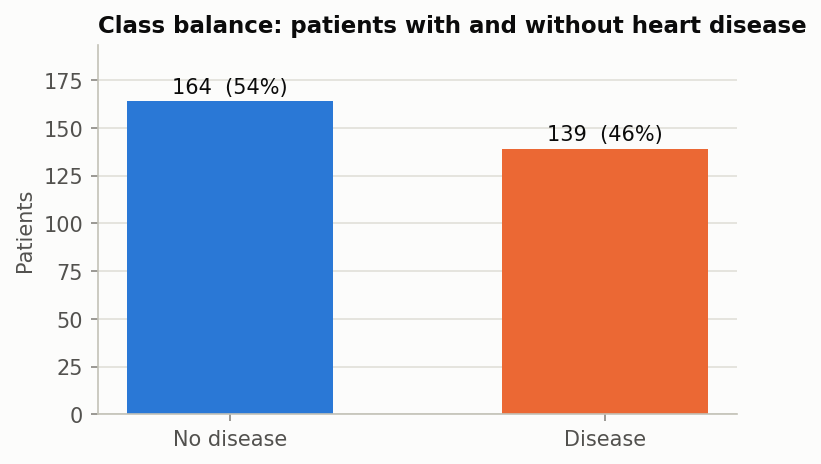

In [5]:
paths = {p.stem: p for p in make_all_figures(df)}
display(Image(paths["class_balance"]))

**Finding:** 54% / 46% is close to balanced, so no resampling or class weights are needed. We'll still use **stratified** cross-validation so every fold keeps that ratio, and report precision, recall and ROC-AUC alongside accuracy.

## 3. Numeric features by class

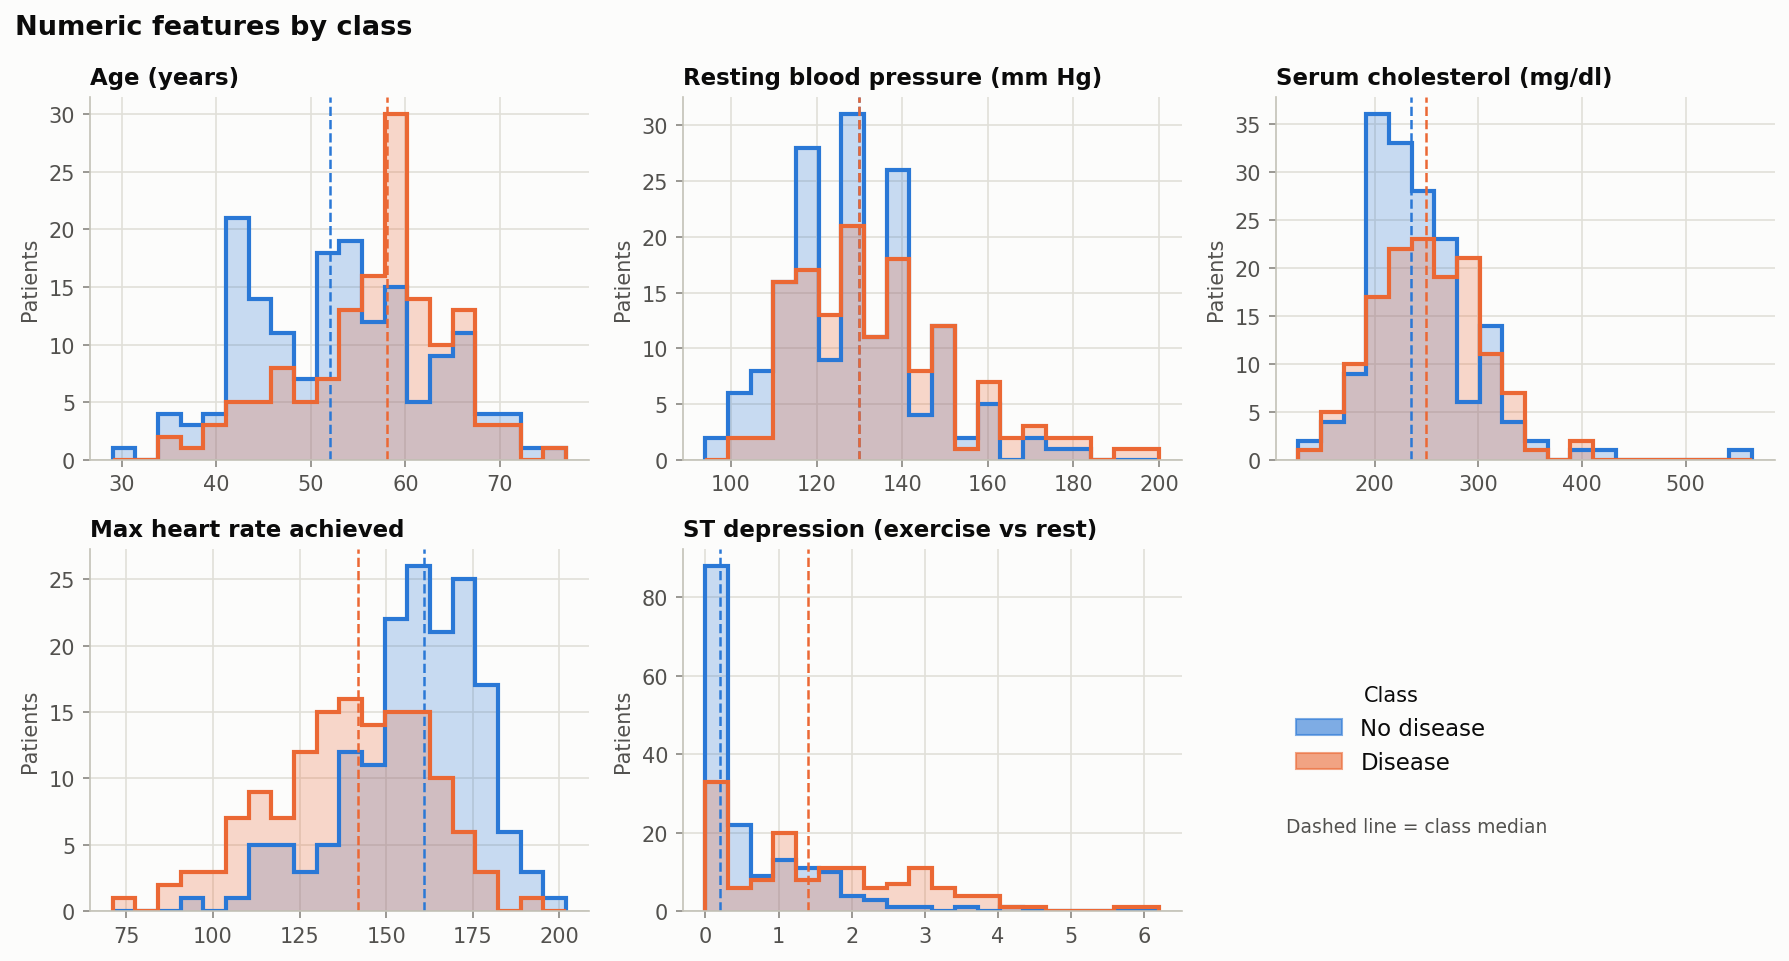

In [6]:
display(Image(paths["numeric_distributions"]))

In [7]:
df.groupby(TARGET)[NUMERIC_FEATURES].median().rename(index={0: "no disease", 1: "disease"})

,age,trestbps,chol,thalach,oldpeak
target,,,,,
no disease,52.0,130.0,234.5,161.0,0.2
disease,58.0,130.0,249.0,142.0,1.4


**Findings**
- **Max heart rate (`thalach`)** is clearly lower for patients with disease (median about 142 vs 161). It's one of the strongest single signals.
- **ST depression (`oldpeak`)** is much higher with disease. Most healthy patients sit at 0, so the distribution is heavily right-skewed.
- **Age** shifts older with disease (about 58 vs 52).
- **Cholesterol** and **resting blood pressure** overlap almost completely, so on their own they're weak predictors.
- A few high values (cholesterol 564, blood pressure 200) are clinically plausible, so we keep them rather than clip them.

## 4. Categorical features: disease rate per level

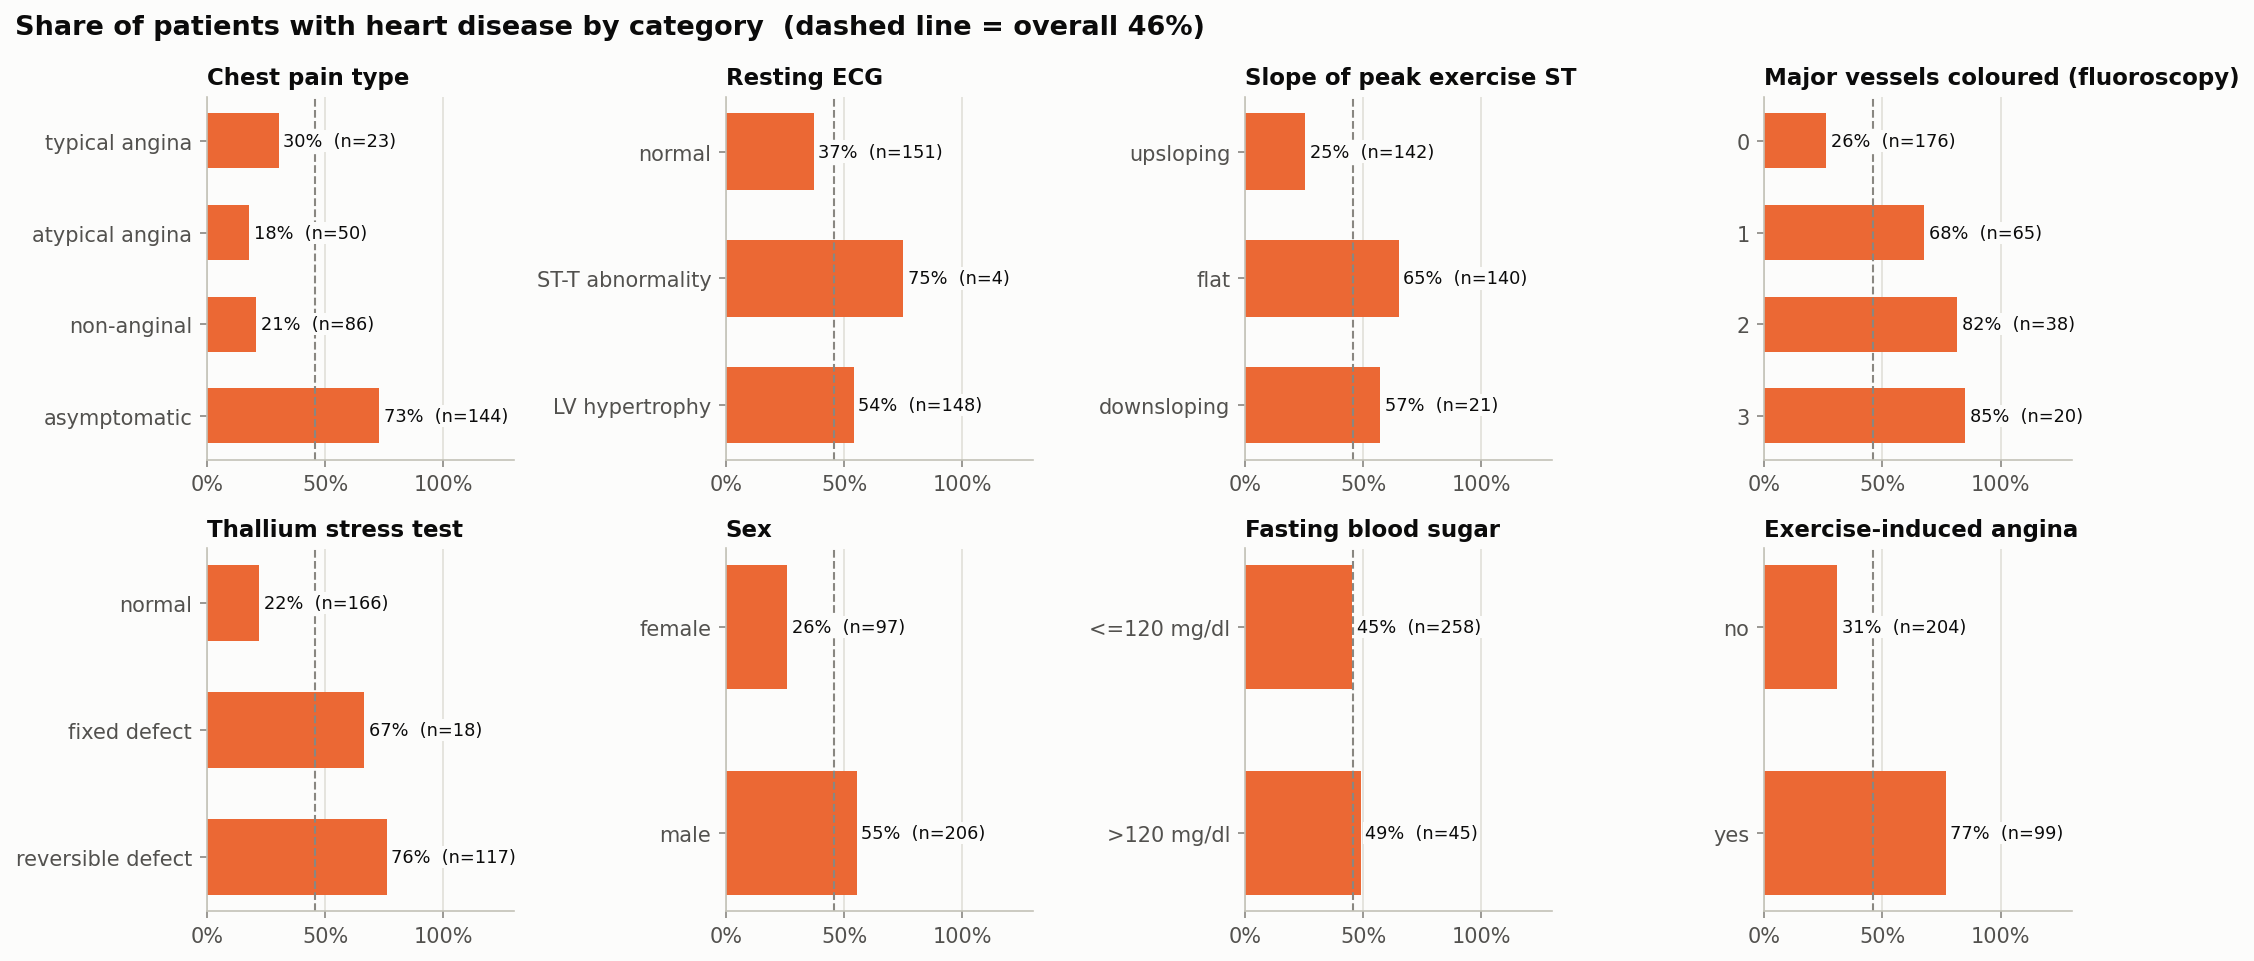

In [8]:
display(Image(paths["categorical_disease_rate"]))

In [9]:
coded = CATEGORICAL_FEATURES + BINARY_FEATURES
pd.concat({c: df[c].value_counts(dropna=False).sort_index() for c in coded}).to_frame("patients").T

cp              restecg         slope           ... thal           \
           1   2   3    4       0  1    2     1    2   3  ...    3   6    7   
patients  23  50  86  144     151  4  148   142  140  21  ...  166  18  117   

              sex       fbs     exang      
         <NA>   0    1    0   1     0   1  
patients    2  97  206  258  45   204  99  

[1 rows x 25 columns]

**Findings**
- **`thal` (reversible defect, 76%)**, **`ca` ≥ 1 vessel (68–85%)**, **exercise angina (77%)** and **flat ST slope (65%)** all sharply raise the disease rate.
- **Chest pain `cp` = asymptomatic has the highest rate (73%).** That sounds backwards, but it matches clinical knowledge: "silent" ischaemia is common in diagnosed patients. It's a good example of why **`cp` must be one-hot encoded**. Its codes 1–4 are *nominal* labels, not an ordered scale.
- **`restecg` = ST-T abnormality has only 4 patients.** Rare levels like this can be missing from a CV training fold, so the encoder must tolerate unseen categories (`handle_unknown="ignore"`).
- **Fasting blood sugar** makes almost no difference (45% vs 49%). It's a candidate for low feature importance.
- **Sex:** 68% of patients are male, and men have a much higher disease rate (55% vs 26%). The model will learn this imbalance. We'll note it in the model card as a **dataset bias / limitation**.

## 5. Correlations

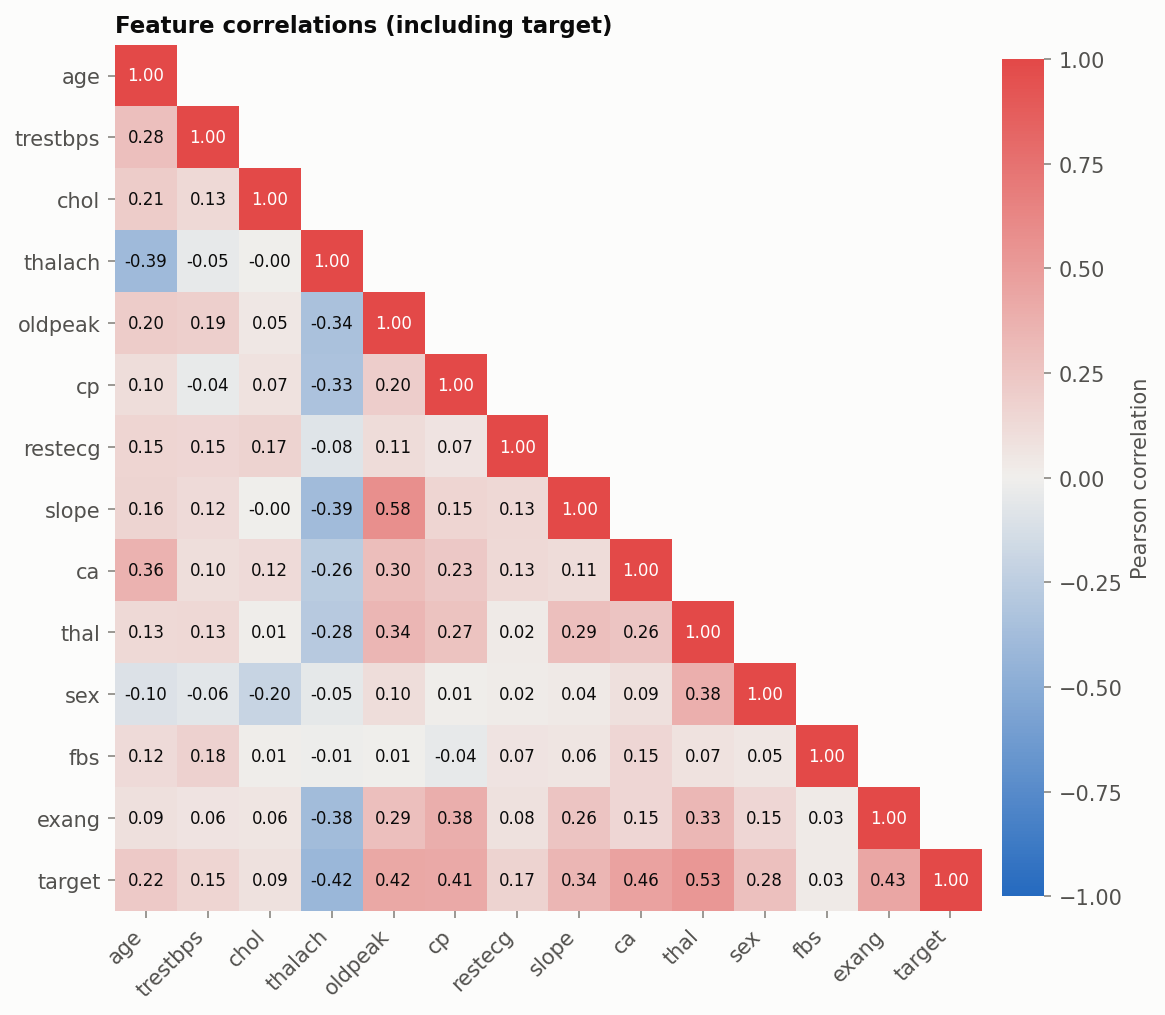

In [10]:
display(Image(paths["correlation_heatmap"]))

In [11]:
target_corr = df.astype(float).corr()[TARGET].drop(TARGET)
target_corr.sort_values(key=abs, ascending=False).to_frame("corr with target")

,corr with target
thal,0.53
ca,0.46
exang,0.43
oldpeak,0.42
thalach,-0.42
cp,0.41
slope,0.34
sex,0.28
age,0.22
restecg,0.17


**Findings**
- The strongest linear relationships with the target are `thal` (0.53), `ca` (0.46), `exang` (0.43), `oldpeak` (0.42), `thalach` (−0.42) and `cp` (0.41). This agrees with the plots above.
- **Caveat:** Pearson correlation on nominal codes (`cp`, `thal`, `restecg`) depends on the arbitrary code order, so treat those values as rough hints only. The per-level disease rates in section 4 are the reliable view.
- No pair of features is highly collinear (|r| ≤ 0.58, between `oldpeak` and `slope`), so we don't need to drop any features.

## 6. Decisions carried into Phase 2

| Observation | Decision |
|---|---|
| 6 missing values in `ca` / `thal` | Impute **inside** the pipeline (median for numeric, most-frequent for categorical) |
| Numeric features on very different scales | `StandardScaler` on `age, trestbps, chol, thalach, oldpeak` |
| `cp, restecg, slope, ca, thal` are coded categories | `OneHotEncoder(handle_unknown="ignore")` |
| `sex, fbs, exang` are already 0/1 | Pass through unchanged |
| Classes about 54/46 | Stratified 5-fold CV; no resampling |
| Missed disease is costlier than a false alarm | Track **recall** and ROC-AUC, not just accuracy |
| Dataset is 68% male, from one hospital | Record as a limitation in the model card |